# Tarea 6 — Física Computacional II

**Nombre:** Martina Guerrero Ramos  
**RUT:** 21.888.130-0  
**Fecha:** 5 de noviembre de 2026

## Bibliotecas y constantes físicas

In [4]:
# Importo las bibliotecas necesarias para analizar el catálogo estelar.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Defino las constantes físicas que utilizaré en los cálculos.
L_SOL_W = 3.828e26  # Luminosidad solar en vatios (W).
T_SOL_K = 5772.0    # Temperatura efectiva del Sol en kelvin (K).
PC_M = 3.085677581491367e16  # Equivalencia de un pársec en metros (m).
B_WIEN = 2.8978e-3  # Constante de desplazamiento de Wien (m K).

# Defino una paleta de colores para mis gráficos.
LAVANDA = "#8276B8"
ROSA = "#D98DA5"
AZUL = "#497C91"
SALVIA = "#8DB8AA"
DORADO = "#E8BD73"
FONDO = "#FAF9FC"

# Configuro el tamaño de las figuras y las letras para facilitar su lectura.
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "figure.constrained_layout.use": True,
    "figure.facecolor": "white",
    "axes.facecolor": FONDO,
    "axes.edgecolor": "#B7B4C5",
    "axes.labelcolor": "#343448",
    "text.color": "#343448",
    "xtick.color": "#666477",
    "ytick.color": "#666477",
    "grid.color": "#DCD9E5",
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Establezco la precisión con la que mostraré los resultados de pandas.
pd.set_option("display.precision", 5)

## Clase `CatalogoEstelar`

Para realizar el análisis, implemento la clase `CatalogoEstelar`, que me permite organizar los datos y calcular las propiedades físicas de las estrellas.

Durante la limpieza, conservo todas las estrellas del catálogo y reemplazo los valores faltantes, infinitos o físicamente inválidos por `NaN`. Considero inválidos los valores de luminosidad, distancia y temperatura que sean menores o iguales a cero.

No reemplazo los datos faltantes por promedios, ya que esto introduciría valores artificiales que podrían alterar los resultados. En los cálculos y estadísticas utilizo únicamente los valores válidos de cada propiedad.

Finalmente, genero un reporte para identificar la cantidad y el porcentaje de valores faltantes antes y después de la limpieza.

In [5]:
class CatalogoEstelar:
    """Clase para trabajar con los datos de un catálogo estelar.

    Parameters
    ----------
    ruta : str, optional
        Ruta del archivo NPZ.
    datos : pandas.DataFrame, optional
        Datos de un catálogo creado manualmente.
    """

    def __init__(self, ruta=None, datos=None):
        """Inicializo el catálogo y limpio sus datos.

        Parameters
        ----------
        ruta : str, optional
            Ruta del archivo.
        datos : pandas.DataFrame, optional
            Datos de entrada.

        Returns
        -------
        None
            Inicializo el catálogo.
        """
        if datos is None and ruta is None:
            raise ValueError("Debo indicar un archivo o DataFrame.")

        self.df = self.cargar_npz(ruta) if datos is None else datos.copy()
        self.reporte_limpieza = self.limpiar_datos()

    def cargar_npz(self, ruta):
        """Cargo los datos de un archivo NPZ.

        Parameters
        ----------
        ruta : str
            Nombre o ruta del archivo.

        Returns
        -------
        pandas.DataFrame
            Datos del catálogo estelar.
        """
        # Leo el archivo y guardo sus datos.
        with np.load(ruta, allow_pickle=True) as archivo:
            datos = {clave: archivo[clave] for clave in archivo.files}

        # Organizo los datos en un DataFrame.
        return pd.DataFrame(datos)

    def limpiar_datos(self):
        """Identifico y limpio los valores faltantes o inválidos.

        Returns
        -------
        pandas.DataFrame
            Cantidad y porcentaje de datos faltantes.
        """
        columnas = ["nombre", "L_Lsol", "d_pc", "T_K"]
        faltantes = set(columnas) - set(self.df.columns)

        if faltantes:
            raise ValueError(f"Faltan columnas: {sorted(faltantes)}")

        # Cuento los datos faltantes antes de limpiar.
        antes = self.df[columnas].isna().sum()

        # Reemplazo los valores inválidos por NaN.
        for col in ["L_Lsol", "d_pc", "T_K"]:
            serie = pd.to_numeric(self.df[col], errors="coerce")
            self.df[col] = serie.where(
                np.isfinite(serie) & (serie > 0), np.nan
            )

        # Considero los nombres vacíos como datos faltantes.
        self.df["nombre"] = self.df["nombre"].replace(
            r"^\s*$", np.nan, regex=True
        )

        # Calculo los faltantes después de limpiar.
        despues = self.df[columnas].isna().sum()

        return pd.DataFrame({
            "faltantes_originales": antes,
            "porcentaje_original": 100 * antes / len(self.df),
            "faltantes_tras_limpieza": despues,
            "porcentaje_final": 100 * despues / len(self.df)
        })

    def calcular_flujo(self):
        """Calculo el flujo bolométrico de las estrellas.

        Returns
        -------
        pandas.Series
            Flujo bolométrico en W/m².
        """
        # Convierto la luminosidad a vatios y la distancia a metros.
        L_W = self.df["L_Lsol"] * L_SOL_W
        d_m = self.df["d_pc"] * PC_M

        # Calculo el flujo recibido de cada estrella.
        self.df["F_bol_W_m2"] = L_W / (4 * np.pi * d_m**2)

        return self.df["F_bol_W_m2"]

    def calcular_radio(self):
        """Calculo el radio estelar mediante Stefan-Boltzmann.

        Returns
        -------
        pandas.Series
            Radio estelar en radios solares.
        """
        # Calculo el radio utilizando la luminosidad y temperatura.
        self.df["R_Rsol"] = (
            np.sqrt(self.df["L_Lsol"]) *
            (T_SOL_K / self.df["T_K"])**2
        )

        return self.df["R_Rsol"]

    def calcular_magnitud(self):
        """Calculo la magnitud bolométrica absoluta.

        Returns
        -------
        pandas.Series
            Magnitud bolométrica absoluta.
        """
        # Calculo la magnitud a partir de la luminosidad.
        self.df["M_bol"] = (
            4.74 - 2.5 * np.log10(self.df["L_Lsol"])
        )

        return self.df["M_bol"]

    def calcular_lambda_max(self):
        """Calculo la longitud de onda máxima mediante la ley de Wien.

        Returns
        -------
        pandas.Series
            Longitud de onda máxima en nanómetros.
        """
        # Aplico la ley de Wien y convierto el resultado a nanómetros.
        self.df["lambda_max_nm"] = (
            B_WIEN / self.df["T_K"] * 1e9
        )

        return self.df["lambda_max_nm"]

    def clasificar_deteccion(self, umbral=1e-4):
        """Clasifico las estrellas según su flujo bolométrico.

        Parameters
        ----------
        umbral : float, optional
            Flujo mínimo detectable en W/m².

        Returns
        -------
        pandas.Series
            Clasificación de las estrellas.
        """
        if not np.isfinite(umbral) or umbral <= 0:
            raise ValueError("El umbral debe ser positivo.")

        if "F_bol_W_m2" not in self.df:
            self.calcular_flujo()

        flujo = self.df["F_bol_W_m2"]

        # Clasifico las estrellas según el umbral elegido.
        clasificacion = np.select(
            [flujo.isna(), flujo >= umbral],
            ["Desconocida", "Detectada"],
            default="No detectada"
        )

        self.df["deteccion"] = clasificacion

        return self.df["deteccion"]

    def estadisticas(self):
        """Calculo las estadísticas de las propiedades numéricas.

        Returns
        -------
        pandas.DataFrame
            Media, mediana, desviación, percentiles y extremos.
        """
        # Selecciono las columnas numéricas del catálogo.
        columnas = self.df.select_dtypes(include="number")

        # Calculo las estadísticas principales.
        resultado = columnas.agg(
            ["mean", "median", "std", "min", "max"]
        ).T

        # Agrego los percentiles solicitados.
        resultado["P25"] = columnas.quantile(0.25)
        resultado["P50"] = columnas.quantile(0.50)
        resultado["P75"] = columnas.quantile(0.75)

        return resultado[
            ["mean", "median", "std", "P25", "P50", "P75", "min", "max"]
        ]

    def extremos_estelares(self):
        """Identifico las estrellas con valores máximos y mínimos.

        Returns
        -------
        pandas.DataFrame
            Nombres y valores de las estrellas extremas.
        """
        filas = []

        # Busco los extremos de luminosidad, temperatura y radio.
        for col in ["L_Lsol", "T_K", "R_Rsol"]:
            validos = self.df.loc[self.df[col].notna()]

            if validos.empty:
                continue

            for tipo, indice in [
                ("Mínimo", validos[col].idxmin()),
                ("Máximo", validos[col].idxmax())
            ]:
                estrella = self.df.loc[indice]

                filas.append({
                    "propiedad": col,
                    "extremo": tipo,
                    "nombre": estrella["nombre"],
                    "valor": estrella[col]
                })

        return pd.DataFrame(filas)

    def resumen_por_temperatura(self, umbral=1e-4):
        """Agrupo las estrellas según su temperatura efectiva.

        Parameters
        ----------
        umbral : float, optional
            Umbral de detección en W/m².

        Returns
        -------
        pandas.DataFrame
            Estadísticas de cada grupo de temperatura.
        """
        self.clasificar_deteccion(umbral)
        datos = self.df.copy()

        # Divido las estrellas en tres grupos de temperatura.
        datos["grupo_temp"] = pd.cut(
            datos["T_K"],
            bins=[0, 5000, 7500, np.inf],
            labels=["Fría", "Intermedia", "Caliente"],
            right=False
        )

        # Excluyo los flujos desconocidos de la fracción detectada.
        datos["detectada_valida"] = np.where(
            datos["F_bol_W_m2"].notna(),
            (datos["deteccion"] == "Detectada").astype(float),
            np.nan
        )

        # Calculo las estadísticas de cada grupo.
        resumen = (
            datos.groupby("grupo_temp", observed=False)
            .agg(
                n_estrellas=("T_K", "count"),
                temperatura_media_K=("T_K", "mean"),
                luminosidad_media_Lsol=("L_Lsol", "mean"),
                flujo_mediano_W_m2=("F_bol_W_m2", "median"),
                n_flujo_valido=("F_bol_W_m2", "count"),
                fraccion_detectada=("detectada_valida", "mean")
            )
            .reset_index()
        )

        return resumen

    def graficar_hr(self):
        """Grafico el diagrama Hertzsprung-Russell.

        Returns
        -------
        matplotlib.figure.Figure
            Diagrama HR.
        """
        # Selecciono estrellas con luminosidad y temperatura válidas.
        datos = self.df.dropna(subset=["T_K", "L_Lsol"])

        fig, ax = plt.subplots(figsize=(8, 5))

        # Ajusto el tamaño y la intensidad según la cantidad de estrellas.
        tamano = 30 if len(datos) <= 100 else 5
        transparencia = 0.85 if len(datos) <= 100 else 0.35

        ax.scatter(
            datos["T_K"], datos["L_Lsol"],
            s=tamano, alpha=transparencia,
            color="#7663B5", edgecolors="none", rasterized=True
        )

        # Utilizo escala logarítmica e invierto la temperatura.
        ax.set(
            xlabel="Temperatura efectiva [K]",
            ylabel="Luminosidad bolométrica [L$_\\odot$]",
            title="Diagrama Hertzsprung-Russell",
            yscale="log"
        )

        ax.invert_xaxis()
        plt.show()

        return fig

    def graficar_histogramas(self, bins=30):
        """Grafico histogramas de las propiedades estelares.

        Parameters
        ----------
        bins : int, optional
            Número de intervalos de los histogramas.

        Returns
        -------
        matplotlib.figure.Figure
            Figura con cinco histogramas.
        """
        if not isinstance(bins, (int, np.integer)) or bins <= 0:
            raise ValueError("bins debe ser un entero positivo.")

        propiedades = [
            ("L_Lsol", "Luminosidad bolométrica",
             "Luminosidad [L$_\\odot$]", AZUL),
            ("d_pc", "Distancia", "Distancia [pc]", SALVIA),
            ("T_K", "Temperatura efectiva", "Temperatura [K]", ROSA),
            ("R_Rsol", "Radio estelar", "Radio [R$_\\odot$]", LAVANDA),
            ("M_bol", "Magnitud bolométrica",
             "Magnitud bolométrica absoluta [mag]", DORADO)
        ]

        # Creo los histogramas de las cinco propiedades.
        fig, ejes = plt.subplots(2, 3, figsize=(14, 8))

        for ax, (col, titulo, etiqueta, color) in zip(ejes.flat, propiedades):
            ax.hist(
                self.df[col].dropna(),
                bins=bins,
                color=color,
                alpha=0.9,
                edgecolor="white"
            )
            ax.set(
                xlabel=etiqueta,
                ylabel="Número de estrellas",
                title=titulo
            )

        ejes.flat[-1].axis("off")
        plt.show()

        return fig

    def graficar_temperatura_flujo(self, umbral=1e-4):
        """Grafico la temperatura y el flujo bolométrico.

        Parameters
        ----------
        umbral : float, optional
            Umbral de detección en W/m².

        Returns
        -------
        matplotlib.figure.Figure
            Figura con dos paneles.
        """
        self.clasificar_deteccion(umbral)

        datos = self.df.dropna(
            subset=["d_pc", "F_bol_W_m2", "T_K"]
        )

        # Creo dos paneles para representar las distribuciones.
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

        # Grafico el histograma de temperaturas.
        ax1.hist(
            self.df["T_K"].dropna(),
            bins=30,
            color=ROSA,
            alpha=0.9,
            edgecolor="white"
        )

        ax1.set(
            xlabel="Temperatura efectiva [K]",
            ylabel="Número de estrellas",
            title="Distribución de temperaturas"
        )

        # Grafico el flujo en función de la distancia.
        puntos = ax2.scatter(
            datos["d_pc"],
            datos["F_bol_W_m2"],
            c=datos["T_K"],
            cmap="magma",
            s=3,
            alpha=0.45,
            rasterized=True
        )

        # Marco el umbral de detección con una línea discontinua.
        ax2.axhline(
            umbral,
            color=AZUL,
            ls="--",
            lw=1.5,
            label=f"Umbral = {umbral:.0e} W m$^{{-2}}$"
        )

        ax2.set(
            xlabel="Distancia [pc]",
            ylabel="Flujo bolométrico [W m$^{-2}$]",
            yscale="log",
            title="Flujo, distancia y temperatura"
        )

        ax2.legend()
        fig.colorbar(
            puntos, ax=ax2,
            label="Temperatura efectiva [K]"
        )

        plt.show()
        return fig

    def graficar_grupos(self, umbral=1e-4):
        """Grafico la cantidad de estrellas y su fracción detectada.

        Parameters
        ----------
        umbral : float, optional
            Umbral de detección en W/m².

        Returns
        -------
        matplotlib.figure.Figure
            Figura con dos gráficos de barras.
        """
        # Obtengo el resumen de los grupos de temperatura.
        resumen = self.resumen_por_temperatura(umbral)

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
        nombres = resumen["grupo_temp"].astype(str)
        colores = [ROSA, LAVANDA, AZUL]

        # Grafico la cantidad de estrellas en cada grupo.
        ax1.bar(nombres, resumen["n_estrellas"], color=colores)
        ax1.set(
            xlabel="Grupo de temperatura",
            ylabel="Número de estrellas",
            title="Cantidad por grupo"
        )

        # Grafico la fracción de estrellas detectadas.
        ax2.bar(
            nombres,
            resumen["fraccion_detectada"].fillna(0),
            color=colores
        )

        ax2.set(
            xlabel="Grupo de temperatura",
            ylabel="Fracción detectada",
            title=f"Detección con umbral {umbral:.0e} W m$^{{-2}}$",
            ylim=(0, 1)
        )

        plt.show()
        return fig

    def guardar_resultados(self, ruta="catalogo_procesado.csv"):
        """Guardo el catálogo procesado en CSV o NPZ.

        Parameters
        ----------
        ruta : str, optional
            Nombre del archivo de salida.

        Returns
        -------
        pathlib.Path
            Ruta del archivo guardado.
        """
        ruta = Path(ruta)

        # Guardo los datos según el formato elegido.
        if ruta.suffix.lower() == ".csv":
            self.df.to_csv(ruta, index=False)

        elif ruta.suffix.lower() == ".npz":
            np.savez_compressed(
                ruta,
                **{c: self.df[c].to_numpy() for c in self.df.columns}
            )

        else:
            raise ValueError("La extensión debe ser .csv o .npz")

        return ruta

    @classmethod
    def desde_dataframe(cls, datos):
        """Creo un catálogo a partir de un DataFrame.

        Parameters
        ----------
        datos : pandas.DataFrame
            Datos del catálogo estelar.

        Returns
        -------
        CatalogoEstelar
            Nueva instancia del catálogo.
        """
        # Compruebo que los datos sean un DataFrame.
        if not isinstance(datos, pd.DataFrame):
            raise TypeError("Los datos deben ser un DataFrame.")

        # Creo una nueva instancia sin leer un archivo NPZ.
        return cls(datos=datos)

## Cargar y limpiar el catálogo original

Cargo el catálogo estelar proporcionado para analizar sus datos. Utilizo la clase `CatalogoEstelar`, que realiza automáticamente la limpieza de los valores faltantes e inválidos. Luego, reviso la cantidad de estrellas, el reporte de limpieza y las primeras filas del catálogo.

In [6]:
# Cargo el catálogo estelar proporcionado por el profesor.
nombre_archivo = "catalogo_100000_estrellas (1).npz"

# Creo el catálogo y realizo la limpieza automáticamente.
catalogo = CatalogoEstelar(nombre_archivo)

# Compruebo la cantidad total de estrellas.
print("Total de estrellas:", len(catalogo.df))

# Muestro la cantidad y el porcentaje de valores faltantes.
print("Reporte de limpieza:")
display(catalogo.reporte_limpieza)

# Reviso las primeras cinco filas del catálogo.
display(catalogo.df.head())

Total de estrellas: 100000
Reporte de limpieza:


,faltantes_originales,porcentaje_original,faltantes_tras_limpieza,porcentaje_final
nombre,0,0.000,0,0.000
L_Lsol,10015,10.015,14960,14.960
d_pc,10013,10.013,15034,15.034
T_K,9972,9.972,15006,15.006


,nombre,L_Lsol,d_pc,T_K
0,Estrella_0000,77.41821,472.49296,5825.85843
1,Estrella_0001,43.94396,476.43002,5742.52252
2,Estrella_0002,NaN,291.20309,9076.06411
3,Estrella_0003,69.76707,162.88920,7043.30630
4,Estrella_0004,9.50832,382.69540,8319.62168


## Propiedades físicas y estadísticas

In [7]:
# Calculo las propiedades físicas de las estrellas.
catalogo.calcular_flujo()
catalogo.calcular_radio()
catalogo.calcular_magnitud()
catalogo.calcular_lambda_max()

# Clasifico las estrellas con el umbral de detección predeterminado.
catalogo.clasificar_deteccion()

# Reviso las primeras estrellas con sus propiedades calculadas.
print("Primeras estrellas con propiedades calculadas:")
display(catalogo.df.head())

# Muestro cuántas estrellas pertenecen a cada clasificación.
print("Clasificaciones de detección:")
print(catalogo.df["deteccion"].value_counts(dropna=False))

# Calculo y muestro las estadísticas de las variables numéricas.
print("Estadísticas de las variables numéricas:")
estadisticas = catalogo.estadisticas()
display(estadisticas)

# Identifico las estrellas con luminosidad, temperatura y radio extremos.
print("Extremos de luminosidad, temperatura y radio:")
display(catalogo.extremos_estelares())

Primeras estrellas con propiedades calculadas:


,nombre,L_Lsol,d_pc,T_K,F_bol_W_m2,R_Rsol,M_bol,lambda_max_nm,deteccion
0,Estrella_0000,77.41821,472.49296,5825.85843,1.10946e-11,8.63683,0.01789,497.40309,No detectada
1,Estrella_0001,43.94396,476.43002,5742.52252,6.19387e-12,6.69725,0.63275,504.62144,No detectada
2,Estrella_0002,NaN,291.20309,9076.06411,NaN,NaN,NaN,319.27937,Desconocida
3,Estrella_0003,69.76707,162.88920,7043.30630,8.41253e-11,5.60951,0.13087,411.42609,No detectada
4,Estrella_0004,9.50832,382.69540,8319.62168,2.07710e-12,1.48422,2.29474,348.30911,No detectada


Clasificaciones de detección:
deteccion
No detectada    72265
Desconocida     27735
Name: count, dtype: int64
Estadísticas de las variables numéricas:


,mean,median,std,P25,P50,P75,min,max
L_Lsol,5.01130e+01,5.02620e+01,2.88206e+01,2.51579e+01,5.02620e+01,7.50313e+01,1.01316e-01,9.99994e+01
d_pc,2.74652e+02,2.74003e+02,1.29877e+02,1.61843e+02,2.74003e+02,3.86933e+02,5.00116e+01,4.99999e+02
T_K,6.50553e+03,6.51113e+03,2.01644e+03,4.75544e+03,6.51113e+03,8.25448e+03,3.00012e+03,9.99990e+03
F_bol_W_m2,6.35083e-11,1.90428e-11,1.25277e-10,8.66340e-12,1.90428e-11,5.45261e-11,1.47035e-14,1.26840e-09
R_Rsol,7.39689e+00,5.05912e+00,6.34303e+00,3.12217e+00,5.05912e+00,9.57396e+00,1.12911e-01,3.67916e+01
M_bol,8.16928e-01,4.86900e-01,1.06164e+00,5.18935e-02,4.86900e-01,1.23832e+00,-2.59993e-01,7.22581e+00
lambda_max_nm,4.97712e+02,4.45053e+02,1.76881e+02,3.51058e+02,4.45053e+02,6.09365e+02,2.89783e+02,9.65894e+02


Extremos de luminosidad, temperatura y radio:


,propiedad,extremo,nombre,valor
0,L_Lsol,Mínimo,Estrella_10217,0.10132
1,L_Lsol,Máximo,Estrella_45903,99.99937
2,T_K,Mínimo,Estrella_5058,3000.12271
3,T_K,Máximo,Estrella_70445,9999.90428
4,R_Rsol,Mínimo,Estrella_62716,0.11291
5,R_Rsol,Máximo,Estrella_2395,36.79163


## Clasificación térmica y representaciones gráficas

Resumen por temperatura con umbral 10^-4 W m^-2:


,grupo_temp,n_estrellas,temperatura_media_K,luminosidad_media_Lsol,flujo_mediano_W_m2,n_flujo_valido,fraccion_detectada
0,Fría,24139,4001.73448,49.99347,1.90998e-11,17463,0.0
1,Intermedia,30397,6250.02370,50.23649,1.91818e-11,21971,0.0
2,Caliente,30458,8744.86970,50.02420,1.88390e-11,21969,0.0


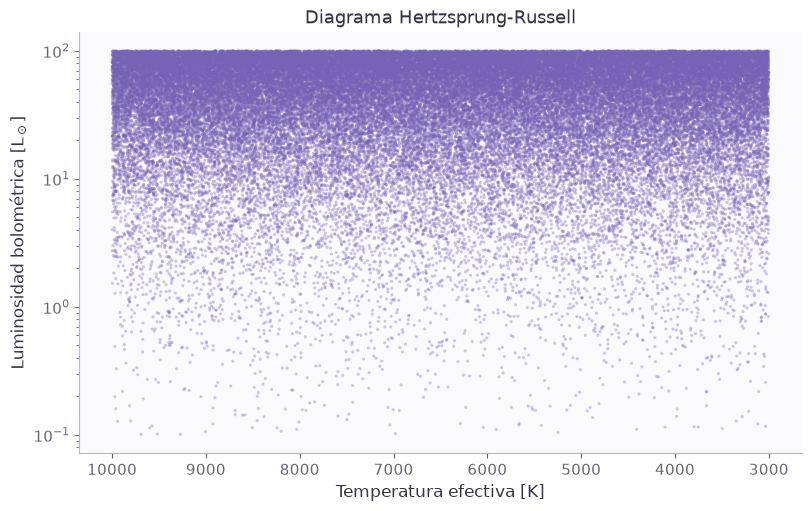

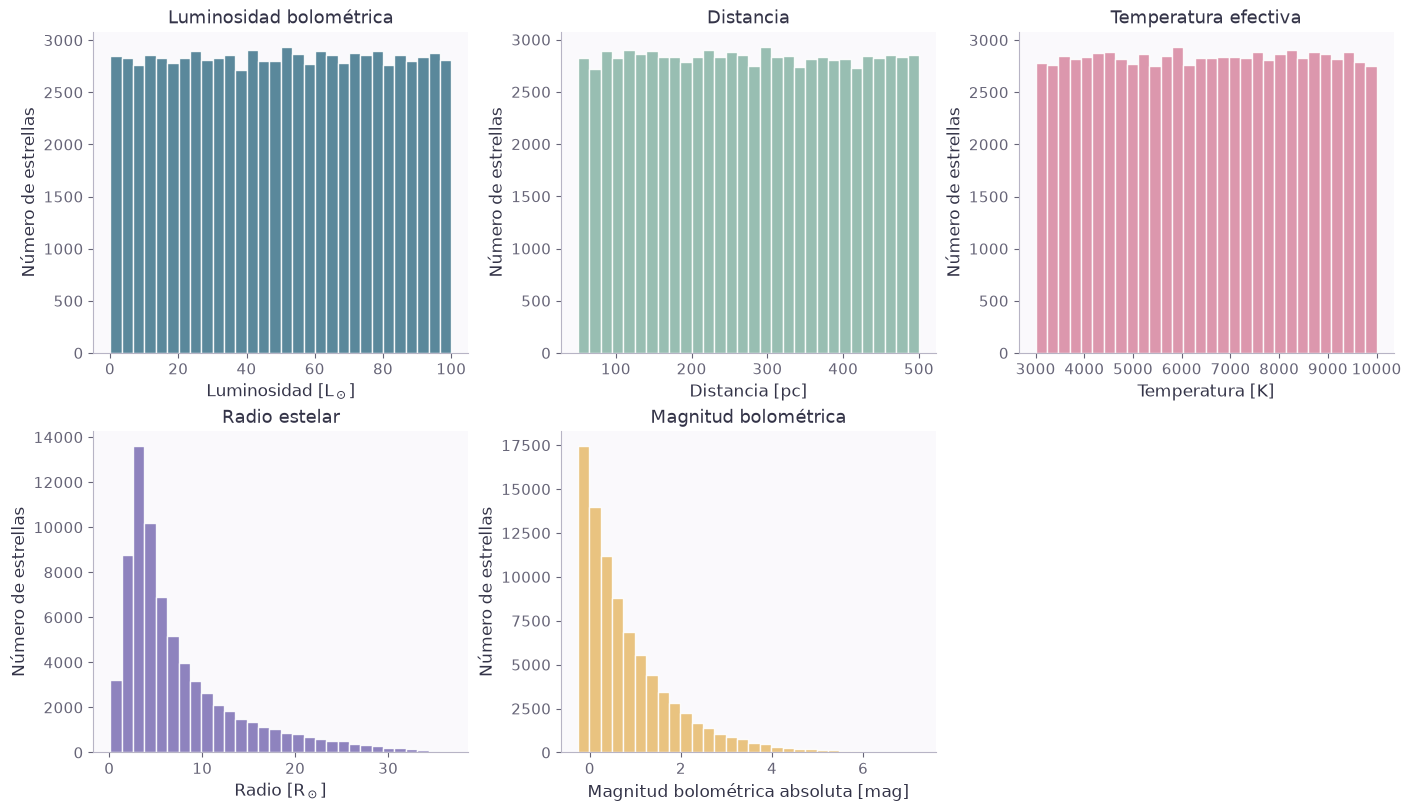

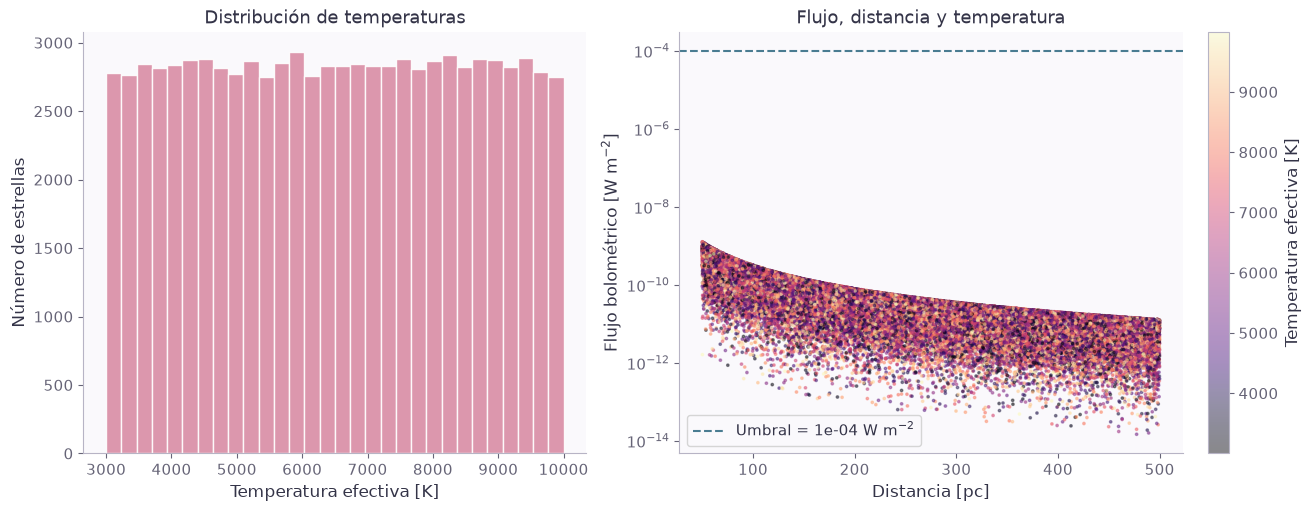

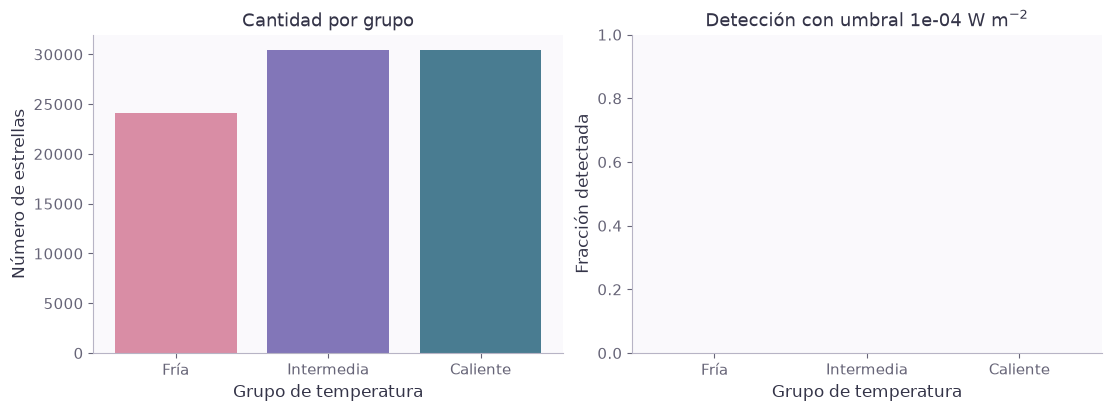

In [8]:
# Agrupo las estrellas según su temperatura y calculo sus estadísticas.
resumen_base = catalogo.resumen_por_temperatura()

print("Resumen por temperatura con umbral 10^-4 W m^-2:")
display(resumen_base)

# Grafico el diagrama Hertzsprung-Russell.
catalogo.graficar_hr()

# Grafico las distribuciones de las propiedades estelares.
catalogo.graficar_histogramas(bins=30)

# Represento la temperatura y el flujo según la distancia.
catalogo.graficar_temperatura_flujo(umbral=1e-4)

# Comparo la cantidad y fracción detectada por grupo de temperatura.
_ = catalogo.graficar_grupos(umbral=1e-4)

## Comparación de umbrales de detección

In [9]:
# Comparo los resultados utilizando dos umbrales de detección.
comparacion = []

for u in [1e-4, 1e-12]:
    # Clasifico las estrellas y obtengo el resumen por temperatura.
    clasificacion = catalogo.clasificar_deteccion(umbral=u)
    resumen = catalogo.resumen_por_temperatura(umbral=u)

    # Cuento las estrellas detectadas, no detectadas y desconocidas.
    comparacion.append({
        "umbral_W_m2": u,
        "detectadas": int((clasificacion == "Detectada").sum()),
        "no_detectadas": int((clasificacion == "No detectada").sum()),
        "desconocidas": int((clasificacion == "Desconocida").sum())
    })

    # Muestro los resultados de cada grupo de temperatura.
    print(f"\nResumen para umbral = {u:.0e} W m^-2")
    display(resumen)

# Organizo la comparación en una tabla.
display(pd.DataFrame(comparacion))

# Restablezco el umbral predeterminado antes de guardar el catálogo.
catalogo.clasificar_deteccion(umbral=1e-4)


Resumen para umbral = 1e-04 W m^-2


,grupo_temp,n_estrellas,temperatura_media_K,luminosidad_media_Lsol,flujo_mediano_W_m2,n_flujo_valido,fraccion_detectada
0,Fría,24139,4001.73448,49.99347,1.90998e-11,17463,0.0
1,Intermedia,30397,6250.02370,50.23649,1.91818e-11,21971,0.0
2,Caliente,30458,8744.86970,50.02420,1.88390e-11,21969,0.0



Resumen para umbral = 1e-12 W m^-2


,grupo_temp,n_estrellas,temperatura_media_K,luminosidad_media_Lsol,flujo_mediano_W_m2,n_flujo_valido,fraccion_detectada
0,Fría,24139,4001.73448,49.99347,1.90998e-11,17463,0.97143
1,Intermedia,30397,6250.02370,50.23649,1.91818e-11,21971,0.97424
2,Caliente,30458,8744.86970,50.02420,1.88390e-11,21969,0.97091


,umbral_W_m2,detectadas,no_detectadas,desconocidas
0,1.00000e-04,0,72265,27735
1,1.00000e-12,70272,1993,27735


0        No detectada
1        No detectada
2         Desconocida
3        No detectada
4        No detectada
             ...     
99995     Desconocida
99996    No detectada
99997    No detectada
99998    No detectada
99999    No detectada
Name: deteccion, Length: 100000, dtype: str

## Método de clase: DataFrame manual de 10 estrellas

,nombre,L_Lsol,d_pc,T_K,F_bol_W_m2,R_Rsol,M_bol,lambda_max_nm,deteccion
0,Ejemplo_01,0.5,1.0,3200,1.59967e-08,2.30058,5.49257,905.56250,Detectada
1,Ejemplo_02,1.0,2.0,4000,7.99836e-09,2.08225,4.74000,724.45000,Detectada
2,Ejemplo_03,3.0,5.0,4800,3.83921e-09,2.50456,3.54720,603.70833,Detectada
3,Ejemplo_04,8.0,12.0,5000,1.77741e-09,3.76927,2.48228,579.56000,Detectada
4,Ejemplo_05,15.0,NaN,5800,NaN,3.83568,1.79977,499.62069,Desconocida
5,Ejemplo_06,25.0,25.0,6800,1.27974e-09,3.60251,1.24515,426.14706,Detectada
6,Ejemplo_07,40.0,50.0,7400,5.11895e-10,3.84786,0.73485,391.59459,Detectada
7,Ejemplo_08,65.0,80.0,7500,3.24933e-10,4.77515,0.20772,386.37333,Detectada
8,Ejemplo_09,100.0,100.0,9000,3.19934e-10,4.11308,-0.26000,321.97778,Detectada
9,Ejemplo_10,120.0,150.0,11000,1.70632e-10,3.01618,-0.45795,263.43636,Detectada


,grupo_temp,n_estrellas,temperatura_media_K,luminosidad_media_Lsol,flujo_mediano_W_m2,n_flujo_valido,fraccion_detectada
0,Fría,3,4000.00000,1.5,7.99836e-09,3,1.0
1,Intermedia,4,6250.00000,22.0,1.27974e-09,3,1.0
2,Caliente,3,9166.66667,95.0,3.19934e-10,3,1.0


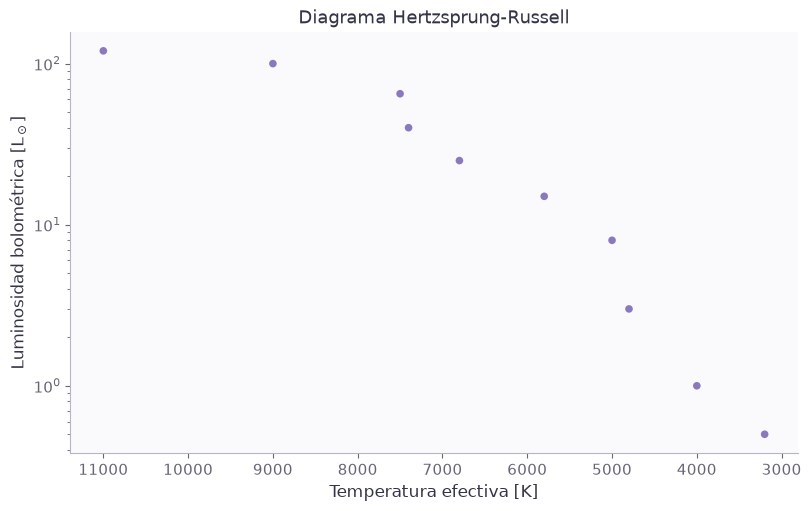

Comprobación correcta: ambos mecanismos de creación funcionan.


In [10]:
# Creo un DataFrame con 10 estrellas de distintas características.
datos_manual = pd.DataFrame({
    "nombre": [f"Ejemplo_{i:02d}" for i in range(1, 11)],
    "L_Lsol": [0.5, 1, 3, 8, 15, 25, 40, 65, 100, 120],
    "d_pc": [1.0, 2.0, 5.0, 12.0, np.nan, 25.0, 50.0, 80.0, 100.0, 150.0],
    "T_K": [3200, 4000, 4800, 5000, 5800, 6800, 7400, 7500, 9000, 11000]
})

# Creo el catálogo manual utilizando el método de clase.
catalogo_manual = CatalogoEstelar.desde_dataframe(datos_manual)

# Calculo las propiedades físicas de las 10 estrellas.
catalogo_manual.calcular_flujo()
catalogo_manual.calcular_radio()
catalogo_manual.calcular_magnitud()
catalogo_manual.calcular_lambda_max()

# Clasifico las estrellas utilizando un umbral de detección de 10^-12 W/m².
catalogo_manual.clasificar_deteccion(umbral=1e-12)

# Muestro los datos y el resumen por temperatura.
display(catalogo_manual.df)
display(catalogo_manual.resumen_por_temperatura(umbral=1e-12))

# Grafico el diagrama Hertzsprung-Russell del catálogo manual.
catalogo_manual.graficar_hr()

# Compruebo que la clase funciona con ambos catálogos.
assert len(catalogo.df) > 0
assert len(catalogo_manual.df) == 10

# Compruebo que la estrella sin distancia mantiene detección desconocida.
assert catalogo_manual.df.loc[4, "deteccion"] == "Desconocida"

# Compruebo que pude calcular los radios de las 10 estrellas.
assert catalogo_manual.df["R_Rsol"].notna().sum() == 10

print("Comprobación correcta: ambos mecanismos de creación funcionan.")

## Guardar resultados

Guardo el catálogo procesado en un archivo CSV, incluyendo los datos originales y las propiedades físicas que calculé. Este archivo se genera por separado, sin modificar el catálogo original proporcionado.

In [11]:
# Guardo el catálogo procesado en un archivo CSV.
ruta_salida = catalogo.guardar_resultados("catalogo_procesado.csv")

# Muestro la ubicación donde guardé el archivo.
print("Datos procesados guardados en:", ruta_salida.resolve())

Datos procesados guardados en: /drive/catalogo_procesado.csv
